# Cobertura de la componente principal en los 1000 casos (baseline frente a v1)

Análisis, **sin reevaluar ningún modelo**, de la cobertura de componente principal a partir de la columna `cobertura_principal` almacenada por los notebooks 32 y 34 en los CSV por caso.

- Delta con el mismo convenio que el notebook 34: **delta > 0 = v1 mejora** (para la cobertura, más es mejor: delta = v1 − baseline).
- Resultados: (A) pooled n = 1000, (B) por fold, (C) consistencia entre folds, y media absoluta de cada modelo.
- Salidas: CSV en `MyDrive/TFM_nnUNet` y una figura.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np, pandas as pd
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt

BASE = Path('/content/drive/MyDrive/TFM_nnUNet')
FOLDS = [0, 1, 2, 3, 4]
COL = 'cobertura_principal'

def leer(etq, f):
    p = BASE / f'{etq}_1000casos_fold{f}_100epochs_metricas_por_caso.csv'
    df = pd.read_csv(p)
    assert COL in df.columns, f'{p.name}: no tiene la columna {COL} (columnas: {list(df.columns)})'
    df['fold'] = f
    return df

base = pd.concat([leer('baseline', f) for f in FOLDS], ignore_index=True).sort_values('case_id').reset_index(drop=True)
v1   = pd.concat([leer('v1', f)       for f in FOLDS], ignore_index=True).sort_values('case_id').reset_index(drop=True)
assert len(base) == 1000 and len(v1) == 1000, (len(base), len(v1))
assert list(base.case_id) == list(v1.case_id), 'case_id no coinciden entre baseline y v1'
assert base[COL].notna().all() and v1[COL].notna().all()
print('OK: 1000 casos emparejados.')

OK: 1000 casos emparejados.


In [3]:
# (A) Pooled, n = 1000
a, b = base[COL].values, v1[COL].values
d = b - a
rng = np.random.default_rng(0)
boot = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(10000)])
ic = np.percentile(boot, [2.5, 97.5])
w = stats.wilcoxon(a, b); t = stats.ttest_rel(a, b)
tabA = pd.DataFrame([{
    'n': len(d), 'media_baseline': a.mean(), 'sd_baseline': a.std(ddof=1),
    'media_v1': b.mean(), 'sd_v1': b.std(ddof=1),
    'delta_medio': d.mean(), 'IC95_bajo': ic[0], 'IC95_alto': ic[1], 'delta_mediano': np.median(d),
    'wilcoxon_p': w.pvalue, 'ttest_rel_p': t.pvalue, 'casos_v1_mejor': int((d > 0).sum()), 'casos_baseline_mejor': int((d < 0).sum()),
}])
print('=== (A) Pooled ===')
print(tabA.T.to_string(header=False))
tabA.to_csv(BASE / 'A_cobertura_POOL_5fold_baseline_vs_v1.csv', index=False)

=== (A) Pooled ===
n                     1.000000e+03
media_baseline        4.620365e-01
sd_baseline           8.337021e-02
media_v1              4.737632e-01
sd_v1                 8.832508e-02
delta_medio           1.172662e-02
IC95_bajo             9.367725e-03
IC95_alto             1.434532e-02
delta_mediano         6.876385e-03
wilcoxon_p            1.166871e-63
ttest_rel_p           2.596889e-19
casos_v1_mejor        7.560000e+02
casos_baseline_mejor  2.430000e+02


In [4]:
# (B) Por fold (n = 200 por fold)
filas = []
for f in FOLDS:
    x = base[base.fold == f][COL].values; y = v1[v1.fold == f][COL].values
    dd = y - x
    filas.append({'fold': f, 'n': len(dd), 'media_baseline': x.mean(), 'media_v1': y.mean(),
                  'delta_medio': dd.mean(), 'delta_mediano': np.median(dd),
                  'wilcoxon_p': stats.wilcoxon(x, y).pvalue, 'ttest_rel_p': stats.ttest_rel(x, y).pvalue})
tabB = pd.DataFrame(filas)
# Holm sobre los 5 folds (Wilcoxon)
p = tabB.wilcoxon_p.values; o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
for r, i in enumerate(o):
    run = max(run, (m - r) * p[i]); adj[i] = min(1, run)
tabB['wilcoxon_p_Holm_5folds'] = adj
print('=== (B) Por fold ===')
print(tabB.round(4).to_string(index=False))
tabB.to_csv(BASE / 'B_cobertura_por_fold_baseline_vs_v1.csv', index=False)

=== (B) Por fold ===
 fold   n  media_baseline  media_v1  delta_medio  delta_mediano  wilcoxon_p  ttest_rel_p  wilcoxon_p_Holm_5folds
    0 200          0.4540    0.4744       0.0203         0.0141         0.0       0.0000                     0.0
    1 200          0.4662    0.4606      -0.0056        -0.0047         0.0       0.0003                     0.0
    2 200          0.4594    0.4708       0.0114         0.0060         0.0       0.0000                     0.0
    3 200          0.4702    0.4826       0.0124         0.0069         0.0       0.0000                     0.0
    4 200          0.4602    0.4804       0.0201         0.0118         0.0       0.0000                     0.0


In [5]:
# (C) Consistencia entre folds
dm = tabB.delta_medio.values
tabC = pd.DataFrame([{'delta_medio_entre_folds': dm.mean(), 'delta_std_entre_folds': dm.std(),
                      'delta_min': dm.min(), 'delta_max': dm.max(), 'n_folds_con_v1_mejor': int((dm > 0).sum())}])
print('=== (C) Consistencia ===')
print(tabC.round(4).T.to_string(header=False))
tabC.to_csv(BASE / 'C_cobertura_consistencia_entre_folds.csv', index=False)

=== (C) Consistencia ===
delta_medio_entre_folds  0.0117
delta_std_entre_folds    0.0094
delta_min               -0.0056
delta_max                0.0203
n_folds_con_v1_mejor     4.0000


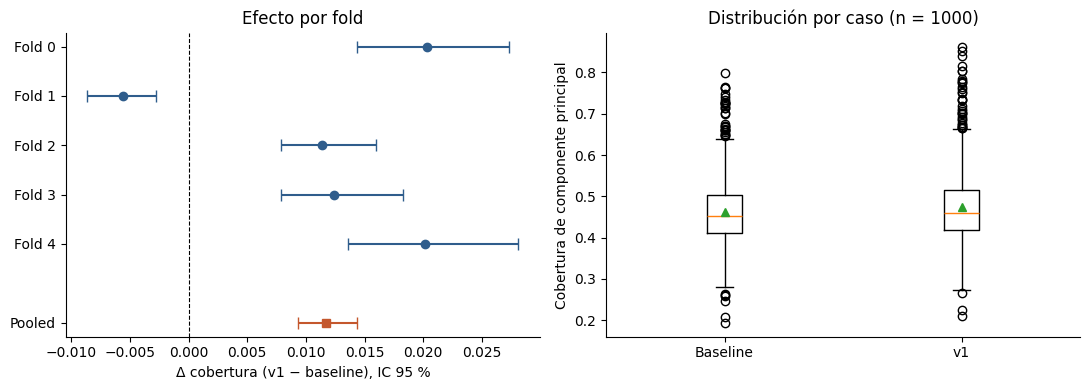

In [6]:
# Figura: delta medio por fold con IC95 (bootstrap) + dispersión por caso
fig, ax = plt.subplots(1, 2, figsize=(11, 4), facecolor='white')
for i, f in enumerate(FOLDS):
    dd = v1[v1.fold == f][COL].values - base[base.fold == f][COL].values
    bs = np.array([dd[rng.integers(0, len(dd), len(dd))].mean() for _ in range(5000)])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    ax[0].errorbar(dd.mean(), i, xerr=[[dd.mean() - lo], [hi - dd.mean()]], fmt='o', color='#2f5d8c', capsize=4)
ax[0].errorbar(d.mean(), len(FOLDS) + 0.6, xerr=[[d.mean() - ic[0]], [ic[1] - d.mean()]], fmt='s', color='#c4572d', capsize=4)
ax[0].axvline(0, color='k', lw=0.8, ls='--')
ax[0].set_yticks(list(range(len(FOLDS))) + [len(FOLDS) + 0.6]); ax[0].set_yticklabels([f'Fold {f}' for f in FOLDS] + ['Pooled'])
ax[0].set_xlabel('Δ cobertura (v1 − baseline), IC 95 %'); ax[0].set_title('Efecto por fold'); ax[0].invert_yaxis()
ax[1].boxplot([base[COL], v1[COL]], tick_labels=['Baseline', 'v1'], showmeans=True)
ax[1].set_ylabel('Cobertura de componente principal'); ax[1].set_title('Distribución por caso (n = 1000)')
for a_ in ax: a_.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(BASE / 'fig_cobertura_1000casos.png', dpi=200, facecolor='white'); plt.show()